# 02 Labels, features and the leakage tests

Grain: one row per building lot and quarterly snapshot (28 snapshots, 2019-01-01 to 2025-10-01; 2.81M rows, 82 features). Features see only what was known at the snapshot; labels look at the **next 12 months**.
This notebook shows (a) the convention that keeps the two windows from touching, (b) how the labels behave, (c) what is missing by design, and (d) the tests that make leakage fail loudly.
Numbers come from [`docs/labels_and_features.md`](../docs/labels_and_features.md), generated by the pipeline.

## The quarter-bucket convention, as a toy

Every event is assigned to the quarter *ending* at or after its date. An event dated exactly on a snapshot belongs to the bucket that ends there, so it is a **feature** at that snapshot and can never be its **label**.

In [1]:
from nbutil import *
SNAPS = pd.date_range("2022-01-01", "2024-01-01", freq="QS")
def bucket_end(d):
    d = pd.Timestamp(d)
    q = SNAPS[SNAPS >= d]
    return q[0] if len(q) else None
t = pd.Timestamp("2023-01-01")
events = ["2022-01-02", "2022-06-30", "2022-12-31", "2023-01-01", "2023-01-02", "2023-09-30", "2024-01-01"]
rows = []
for e in events:
    b = bucket_end(e)
    where = "feature (past 12 months)" if t - pd.DateOffset(months=12) < b <= t else ("LABEL (next 12 months)" if t < b <= t + pd.DateOffset(months=12) else "outside")
    rows.append((e, b.date() if b is not None else None, where))
pd.DataFrame(rows, columns=["event date", "bucket ends", f"role at snapshot {t.date()}"])

,event date,bucket ends,role at snapshot 2023-01-01
0,2022-01-02,2022-04-01,feature (past 12 months)
1,2022-06-30,2022-07-01,feature (past 12 months)
2,2022-12-31,2023-01-01,feature (past 12 months)
3,2023-01-01,2023-01-01,feature (past 12 months)
4,2023-01-02,2023-04-01,LABEL (next 12 months)
5,2023-09-30,2023-10-01,LABEL (next 12 months)
6,2024-01-01,2024-01-01,LABEL (next 12 months)


## The leak that needed care: no-access closure

"The inspector could not gain access" is only known when a complaint problem **closes**. Keyed on the receipt date, a snapshot would "know" the outcome of a complaint that was still open. The features therefore use the closure date. Toy:

In [2]:
toy = pd.DataFrame({"problem": ["A", "B", "C"], "received": pd.to_datetime(["2022-11-20", "2022-12-10", "2022-12-28"]),
                    "closed": pd.to_datetime(["2022-12-01", "2023-02-15", "2022-12-30"]), "no_access": [True, True, False]})
t = pd.Timestamp("2023-01-01")
toy["wrong (receipt date)"] = toy.received <= t
toy["right (closed by t)"] = toy.closed <= t
print("no-access problems counted at t by the WRONG rule:", int((toy["wrong (receipt date)"] & toy.no_access).sum()),
      "| by the RIGHT rule:", int((toy["right (closed by t)"] & toy.no_access).sum()))
toy

no-access problems counted at t by the WRONG rule: 2 | by the RIGHT rule: 1


,problem,received,closed,no_access,wrong (receipt date),right (closed by t)
0,A,2022-11-20,2022-12-01,True,True,True
1,B,2022-12-10,2023-02-15,True,True,False
2,C,2022-12-28,2022-12-30,False,True,True


Problem B was received before the snapshot but only closed (as no access) in February, so the wrong rule would leak a 2023 outcome into a 2023-01-01 feature.

## Label behaviour

In [3]:
P = DOCS / "labels_and_features.md"
lab = md_table(P, "### Label prevalence, overall and by borough")
for c in lab.columns[1:]:
    lab[c] = lab[c].map(num)
lab

,slice,rows,vacate,aep,omo,litigation,serious_any,mean complaint problems next 12m
0,all,2809580.0,0.28,0.18,6.13,3.33,7.83,4.21
1,BK,2173988.0,0.18,0.13,4.53,2.05,5.62,2.43
2,BX,635592.0,0.61,0.34,11.62,7.71,15.38,10.30


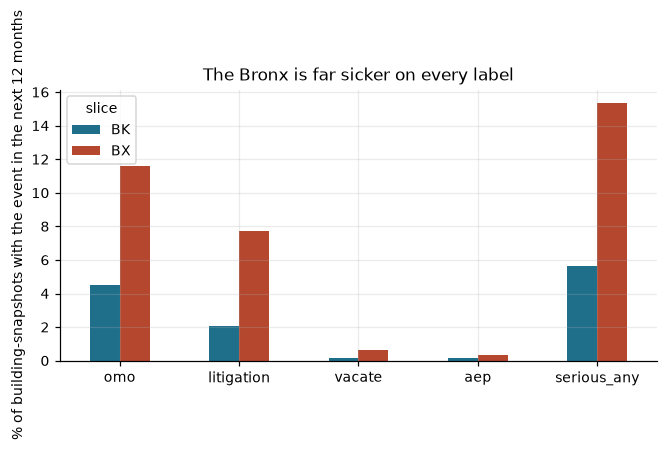

In [4]:
d = lab[lab.slice != "all"].set_index("slice")[["omo", "litigation", "vacate", "aep", "serious_any"]]
d.T.plot.bar(figsize=(7, 3.2), color=[BLUE, RED], rot=0)
plt.ylabel("% of building-snapshots with the event in the next 12 months"); plt.title("The Bronx is far sicker on every label"); plt.show()

78% of `any serious event` is emergency-repair (OMO) charges. HPD enforcement is rule driven off violation counts: AEP selects by open class B and C violations and repairs follow uncorrected hazardous violations. So **a violation count predicts these labels almost by construction**, which is why the Phase 3 baseline is hard to beat, and why Phase 4 needed a less circular target.

## Missing by design

A feature window that reaches back before a source's first covered date is NULL, not 0: "no events" and "not observed" must not look alike.

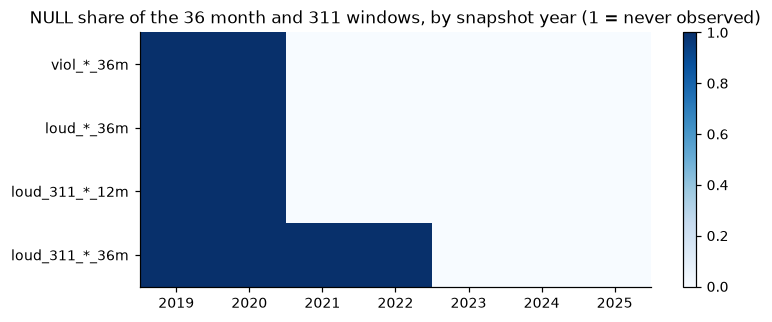

In [5]:
miss = md_table(P, "### Missing-by-design windows")
miss = miss.set_index("year").astype(float)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7.5, 3))
im = ax.imshow(miss.iloc[:, :4].T.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(miss))); ax.set_xticklabels(miss.index); ax.set_yticks(range(4)); ax.set_yticklabels(miss.columns[:4]); ax.grid(False)
ax.set_title("NULL share of the 36 month and 311 windows, by snapshot year (1 = never observed)")
plt.colorbar(im); plt.show()

## The sanity baseline (not a model)

A single column used as a score: HPD violations in the prior 12 months, on the last two snapshots.

In [6]:
md_table(P, "### Smoke baseline", 0)

,snapshot,score,base rate,ROC-AUC,PR-AUC,precision at top 1%
0,2025-07-01,viol_n_12m (the baseline),0.0860,0.8605,0.5527,0.8679
1,2025-07-01,"loud_prob_n_12m (complaints, for context)",0.0860,0.8793,0.5463,0.8294
2,2025-07-01,"prior_omo_n_12m (prior repairs, for context)",0.0860,0.6731,0.3067,0.7978
3,2025-07-01,constant (no information),0.0860,0.5000,0.0860,0.0868
4,2025-10-01,viol_n_12m (the baseline),0.0825,0.8570,0.5458,0.8767
5,2025-10-01,"loud_prob_n_12m (complaints, for context)",0.0825,0.8778,0.5385,0.8304
6,2025-10-01,"prior_omo_n_12m (prior repairs, for context)",0.0825,0.6869,0.3165,0.7880
7,2025-10-01,constant (no information),0.0825,0.5000,0.0825,0.0888


## The tests that guard the pipeline

All run on a synthetic raw fixture with hand-placed edge dates, no real data needed (`make test`). The most important:

In [7]:
import ast
src = (ROOT / "tests" / "test_features.py").read_text()
tests = [(n.name, (ast.get_docstring(n) or "").split("\n")[0]) for n in ast.parse(src).body if isinstance(n, ast.FunctionDef) and n.name.startswith("test_")]
pd.DataFrame(tests, columns=["test", "what it checks"]).set_index("test")

,what it checks
test,
test_no_duplicate_keys_and_matching_tables,
test_spine_rules,
test_sql_matches_bruteforce_oracle_everywhere,
test_static_columns_match_spine,
test_label_window_is_the_next_feature_window,Structural proof that feature windows end at t...
test_hand_checked_edge_cases,"Only the hand-placed rows for one lot, expecte..."
test_features_at_t_ignore_everything_after_t,
test_staging_cleaning_rules,
test_snapshot_grid_validation,


Mutation check (done by hand and recorded in the docs): deliberately breaking the SQL (features reading one bucket ahead, a label window that overlaps t, no-access keyed on the receipt date) makes the matching test fail; restoring it makes it pass.
Real-data checks: the pandas brute-force oracle found 0 mismatches on 100 sampled (building, snapshot) rows across 76 columns, and 0 label-identity exceptions over 2.4M snapshot pairs.

## Known approximations (not errors)
Open-violation counts are approximate and undercounted before 2018; the spine uses today's PLUTO; static fields are current-state; the source tables are edited in place. All are listed in section 7 of the doc.